In [ ]:
# requires transformers>=5.2:  pip install -U "transformers>=5.2"
from transformers import pipeline
import torch

# Load the model
classifier = pipeline(
    "text-classification",
    model="cirimus/ultrabert-380M-go-emotions",
    top_k=5,
    trust_remote_code=True
)

Loading weights:   0%|          | 0/220 [00:00<?, ?it/s]

In [ ]:
text = "I am so happy and excited about this opportunity!"
predictions = classifier(text)

# Print top 5 detected emotions
sorted_preds = sorted(predictions[0], key=lambda x: x['score'], reverse=True)
top_5 = sorted_preds[:5]

print("\nTop 5 emotions detected:")
for pred in top_5:
    print(f"\t{pred['label']:10s} : {pred['score']:.3f}")

# Example output:
# Top 5 emotions detected:
#        excitement : 0.885
#        joy        : 0.753
#        admiration : 0.015
#        love       : 0.015
#        gratitude  : 0.009


Top 5 emotions detected:
	excitement : 0.885
	joy        : 0.753
	admiration : 0.015
	love       : 0.015
	gratitude  : 0.009


README.md:   0%|          | 0.00/9.40k [00:00<?, ?B/s]

simplified/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.77MB            

simplified/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

simplified/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  350kB            

simplified/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

simplified/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  347kB            

simplified/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/43410 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5426 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

True
AUC Score for admiration: 0.9623551905696939
AUC Score for amusement: 0.9865520398640677
AUC Score for anger: 0.9469247842741818
AUC Score for annoyance: 0.8732009986293323
AUC Score for approval: 0.8644888296188532
AUC Score for caring: 0.9516264942190868
AUC Score for confusion: 0.9494412099310714
AUC Score for curiosity: 0.9590240255454563
AUC Score for desire: 0.9599731260370825
AUC Score for disappointment: 0.8970484864612466
AUC Score for disapproval: 0.9143098742850506
AUC Score for disgust: 0.959456890949
AUC Score for embarrassment: 0.9237025522739809
AUC Score for excitement: 0.939282093177624
AUC Score for fear: 0.9756580429603425
AUC Score for gratitude: 0.9922536945812809
AUC Score for grief: 0.9996925536493881
AUC Score for joy: 0.9646389707322021
AUC Score for love: 0.9907982464521752
AUC Score for nervousness: 0.9736668490329226
AUC Score for optimism: 0.9377714587013477
AUC Score for pride: 0.9074916836074663
AUC Score for realization: 0.8398360077817963
AUC Score

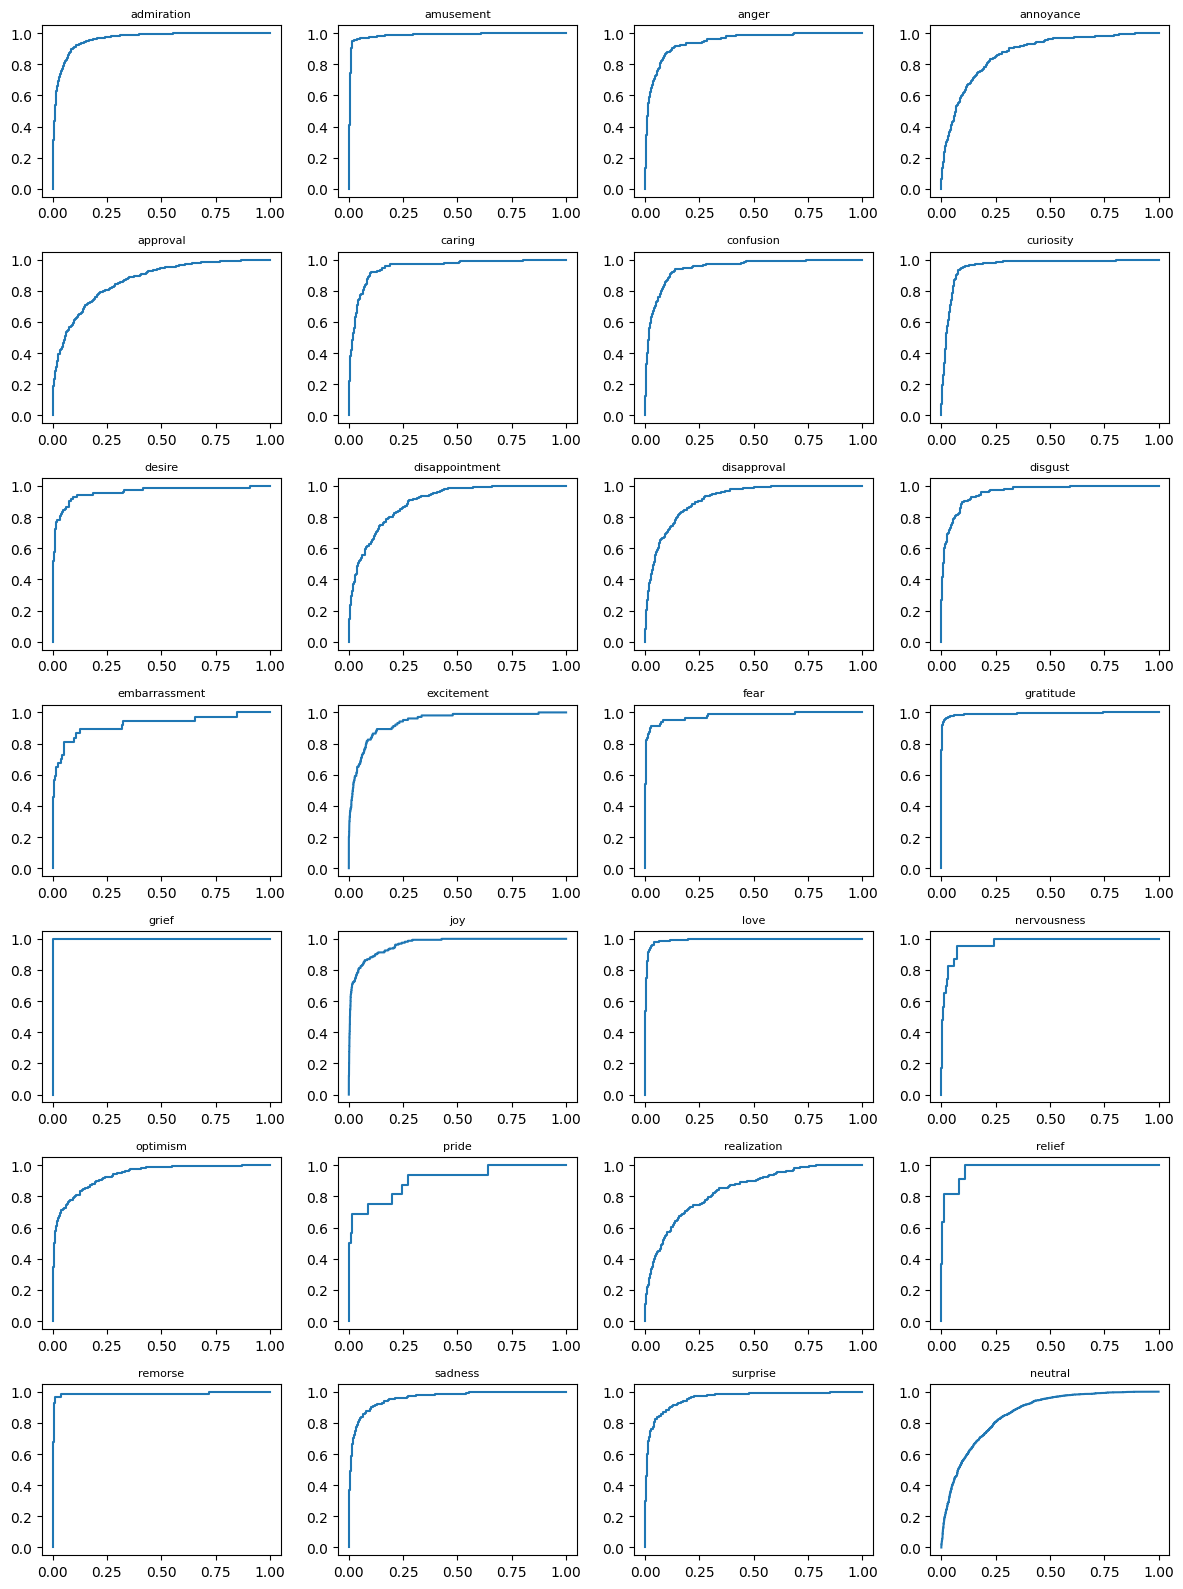

Threshold for admiration: 0.4
Corresponding F1 Score: 0.758893280632411
Threshold for amusement: 0.4
Corresponding F1 Score: 0.80625
Threshold for anger: 0.30000000000000004
Corresponding F1 Score: 0.5355450236966824
Threshold for annoyance: 0.2
Corresponding F1 Score: 0.4043583535108959
Threshold for approval: 0.25
Corresponding F1 Score: 0.4130162703379224
Threshold for caring: 0.25
Corresponding F1 Score: 0.5317220543806647
Threshold for confusion: 0.4
Corresponding F1 Score: 0.47761194029850745
Threshold for curiosity: 0.4
Corresponding F1 Score: 0.5648854961832062
Threshold for desire: 0.45000000000000007
Corresponding F1 Score: 0.5882352941176471
Threshold for disappointment: 0.15000000000000002
Corresponding F1 Score: 0.37889688249400477
Threshold for disapproval: 0.2
Corresponding F1 Score: 0.4437596302003082
Threshold for disgust: 0.25
Corresponding F1 Score: 0.4953271028037383
Threshold for embarrassment: 0.45000000000000007
Corresponding F1 Score: 0.6153846153846154
Threshol

In [ ]:
from datasets import load_dataset
import numpy as np
from sklearn.metrics import f1_score, roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# setting up
ds = load_dataset("google-research-datasets/go_emotions", "simplified")
# take the model and tokenizer out of the pipeline
model, tokenizer = classifier.model, classifier.tokenizer
k = model.config.num_labels
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device).eval()
# emotion names in the dataset's order, used for printing
names = ds["train"].features["labels"].feature.names
model_names = [model.config.id2label[i] for i in range(k)]
print(model_names == names)

# turn dataset's labels into grid
def labels(d):
    y = np.zeros((d.num_rows, k))
    for i, labs in enumerate(d["labels"]):
        y[i, labs] = 1
    return y

# BERT
def probs(texts, bs=64):
    out = []
    for i in range(0, len(texts), bs):
        b = tokenizer(texts[i:i+bs], return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
        with torch.no_grad():
            out.append(torch.sigmoid(model(**b).logits).cpu().numpy())
    return np.vstack(out)

# answer key
vy, ty = labels(ds["validation"]), labels(ds["test"])
# BERT's probabilities
vp, tp = probs(ds["validation"]["text"]), probs(ds["test"]["text"])
# reorder columns if the model's label order differs from the dataset's
if model_names != names:
    idx = [model_names.index(n) for n in names]
    vp, tp = vp[:, idx], tp[:, idx]

# roc curves and auc on test
fig, axs = plt.subplots(7, 4, figsize=(12, 16))
for i in range(k):
    fpr, tpr, _ = roc_curve(ty[:, i], tp[:, i])
    # 28 emotions fill a 7x4 grid, so row = i // 4 and column = i % 4
    axs[i // 4, i % 4].plot(fpr, tpr)
    axs[i // 4, i % 4].set_title(names[i], fontsize=8)
    print(f"AUC Score for {names[i]}: {roc_auc_score(ty[:, i], tp[:, i])}")
plt.tight_layout()
plt.show()

# cutoff per emotion (using validation)
grid = np.linspace(0.1, 0.9, 17)
th = []
for i in range(k):
    # f1 at each candidate cutoff for this emotion
    f1s = [f1_score(vy[:, i], vp[:, i] >= t) for t in grid]
    best = int(np.argmax(f1s))
    th.append(grid[best])
    print(f"Threshold for {names[i]}: {grid[best]}")
    print(f"Corresponding F1 Score: {f1s[best]}")

# f1 on test using the cutoffs from validation
f1 = []
for i in range(k):
    f1.append(f1_score(ty[:, i], tp[:, i] >= th[i]))
    print(f"F1 Scores on Test Data for {names[i]}: {f1[i]}")
# every emotion counts equally
print(f"\nMacro F1 Score: {np.mean(f1)}")